# Detection results: concise comparison

This notebook presents the agreed headline results without retraining any model. It reads the saved baseline and detection artefacts and focuses on three transparent baselines, the four physical-signal detection models, one XGBoost feature-variant sensitivity comparison, and three principal generalisation questions.

The principal split interpretations are: chronological future prediction, grouped AHU generalisation, and held-out-building transfer. The additional one-fold `ahu_held_out` result remains available in the raw CSVs but is treated as a supplementary grouped check rather than another headline panel.

In [12]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'configs').exists() and (ROOT.parent / 'configs').exists():
    ROOT = ROOT.parent
BASELINE_DIR = ROOT / 'results' / 'baselines'
DETECTION_DIR = ROOT / 'results' / 'detection'
SPLIT_DIR = ROOT / 'data' / 'interim' / 'evaluation_splits'

def require_artifacts(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(
            'Run the baseline and detection commands before executing this notebook.\n'
            + '\n'.join(f'- {path}' for path in missing)
        )

require_artifacts(
    BASELINE_DIR / 'baseline_manifest.json',
    BASELINE_DIR / 'baseline_metrics_by_fold.csv',
    BASELINE_DIR / 'baseline_metrics_summary.csv',
    DETECTION_DIR / 'detection_manifest.json',
    DETECTION_DIR / 'detection_metrics_by_fold.csv',
    DETECTION_DIR / 'detection_metrics_summary.csv',
    SPLIT_DIR / 'evaluation_splits.csv',
)

with (BASELINE_DIR / 'baseline_manifest.json').open() as handle:
    baseline_manifest = json.load(handle)
with (DETECTION_DIR / 'detection_manifest.json').open() as handle:
    detection_manifest = json.load(handle)
baseline_folds = pd.read_csv(BASELINE_DIR / 'baseline_metrics_by_fold.csv')
baseline_summary = pd.read_csv(BASELINE_DIR / 'baseline_metrics_summary.csv')
detection_folds = pd.read_csv(DETECTION_DIR / 'detection_metrics_by_fold.csv')
detection_summary = pd.read_csv(DETECTION_DIR / 'detection_metrics_summary.csv')
splits = pd.read_csv(SPLIT_DIR / 'evaluation_splits.csv')

DESIGN_ORDER = ['chronological', 'nested_grouped', 'building_held_out']
DESIGN_LABELS = {
    'chronological': 'Chronological',
    'nested_grouped': 'Grouped AHU',
    'building_held_out': 'Building held-out',
}
MODEL_LABELS = {
    'normal_range_rule': 'Normal operating-range rule',
    'isolation_forest': 'Isolation Forest',
    'xgboost': 'XGBoost',
    'lstm_autoencoder': 'LSTM autoencoder',
}
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

print(f'Rows in frozen split assignments across all designs: {len(splits):,}')
print(f'Headline baselines: {", ".join(baseline_manifest["baseline_names"])}')
print(f'Detection models: {", ".join(detection_manifest["models_requested"])}')
print(f'Fold-level baseline rows: {len(baseline_folds):,}; detection rows: {len(detection_folds):,}')

Rows in frozen split assignments across all designs: 3,549,550
Headline baselines: majority_class, normal_range_rule, actuator_pump_only
Detection models: normal_range_rule, isolation_forest, xgboost, lstm_autoencoder
Fold-level baseline rows: 30; detection rows: 60


## What each principal split means

| Split | Interpretation |
| --- | --- |
| Chronological | Train on earlier rows and test on later rows from the same AHUs. This is a future-prediction test and does not use future rows during fitting. |
| Grouped AHU | The five-fold `nested_grouped` design holds out complete AHU groups. It tests transfer to unseen AHUs, although the building may also appear in training. |
| Building held-out | Each fold tests on one complete building while training on the other buildings. This is the strongest transfer test in this repository. |

The saved `ahu_held_out` result is a supplementary one-fold grouped check. It is not shown as a fourth headline interpretation.

## Three headline baselines

The baseline runner now reports only: the majority-class lower bound, the transparent normal operating-range rule, and the actuator/pump-only logistic baseline. Missingness-only and temperature-only diagnostics were removed from the headline runner; missingness remains visible in the audit and operational-context sensitivity results.

In [13]:
HEADLINE_BASELINES = ['majority_class', 'normal_range_rule', 'actuator_pump_only']
headline_baselines = baseline_summary[baseline_summary['baseline'].isin(HEADLINE_BASELINES)].copy()
headline_baselines = headline_baselines[headline_baselines['design'].isin(DESIGN_ORDER)]
headline_baselines['design_label'] = headline_baselines['design'].map(DESIGN_LABELS)
headline_baselines['method'] = headline_baselines['baseline'].map({
    'majority_class': 'Majority class',
    'normal_range_rule': 'Normal operating-range rule',
    'actuator_pump_only': 'Actuator/pump logistic',
})
display(
    headline_baselines[['design_label', 'method', 'folds', 'mean_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']]
    .sort_values(['design_label', 'mean_f1'], ascending=[True, False])
    .style.format({column: '{:.3f}' for column in ['mean_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']})
)

,design_label,method,folds,mean_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_false_positive_rate
5,Building held-out,Normal operating-range rule,3,0.430,0.581,0.414,0.509,0.347
3,Building held-out,Actuator/pump logistic,3,0.029,0.502,0.180,0.016,0.012
4,Building held-out,Majority class,3,0.000,0.500,0.000,0.000,0.000
6,Chronological,Actuator/pump logistic,1,0.398,0.617,0.754,0.271,0.037
8,Chronological,Normal operating-range rule,1,0.178,0.510,0.336,0.121,0.101
7,Chronological,Majority class,1,0.000,0.500,0.000,0.000,0.000
9,Grouped AHU,Actuator/pump logistic,5,0.494,0.649,0.677,0.393,0.095
11,Grouped AHU,Normal operating-range rule,5,0.448,0.628,0.679,0.336,0.080
10,Grouped AHU,Majority class,5,0.000,0.500,0.000,0.000,0.000


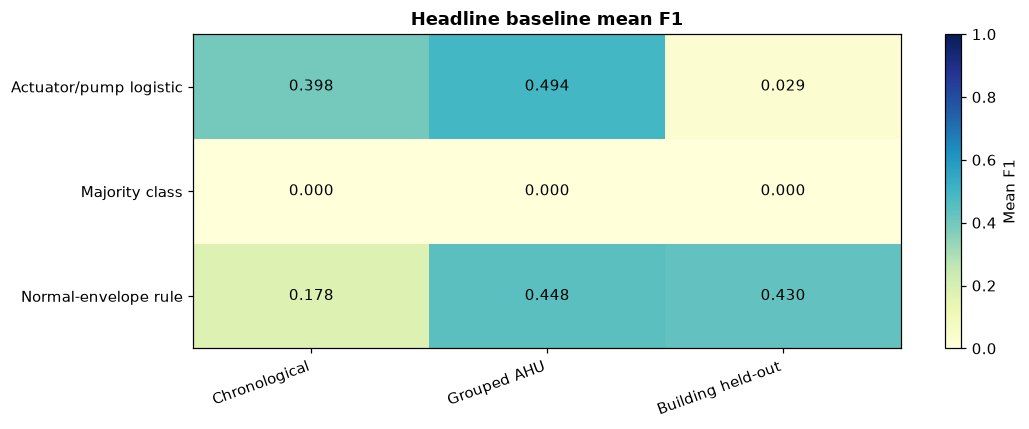

In [14]:
baseline_f1 = headline_baselines.pivot(index='method', columns='design', values='mean_f1').reindex(columns=DESIGN_ORDER)
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(baseline_f1.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_title('Headline baseline mean F1')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(baseline_f1.index)), baseline_f1.index)
for row in range(baseline_f1.shape[0]):
    for col in range(baseline_f1.shape[1]):
        value = baseline_f1.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > .55 else 'black')
fig.colorbar(im, ax=ax, label='Mean F1')
plt.tight_layout()
plt.show()

## Main model comparison: physical-signal features

The headline model comparison uses the physical-signal variant only. It includes raw measured signals and row-local physical relationships, without missingness indicators, mode flags or time-of-day context.

In [15]:
physical = detection_summary[
    (detection_summary['variant'] == 'physical_signal')
    & detection_summary['design'].isin(DESIGN_ORDER)
].copy()
physical['design_label'] = physical['design'].map(DESIGN_LABELS)
physical['model_label'] = physical['model'].map(MODEL_LABELS)
display(
    physical[['design_label', 'model_label', 'folds', 'scored_rows', 'mean_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']]
    .sort_values(['design_label', 'mean_f1'], ascending=[True, False])
    .style.format({column: '{:.3f}' for column in ['mean_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']})
)

,design_label,model_label,folds,scored_rows,mean_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_false_positive_rate
10,Building held-out,Normal operating-range rule,3,354955,0.430,0.581,0.414,0.509,0.347
11,Building held-out,XGBoost,3,354955,0.372,0.599,0.725,0.322,0.123
8,Building held-out,Isolation Forest,3,354955,0.199,0.549,0.360,0.187,0.090
9,Building held-out,LSTM autoencoder,3,354504,0.184,0.541,0.254,0.208,0.126
17,Chronological,XGBoost,1,71015,0.815,0.903,0.690,0.993,0.186
16,Chronological,Normal operating-range rule,1,71015,0.178,0.510,0.336,0.121,0.101
15,Chronological,LSTM autoencoder,1,70564,0.075,0.484,0.199,0.047,0.079
14,Chronological,Isolation Forest,1,71015,0.041,0.504,0.399,0.022,0.014
23,Grouped AHU,XGBoost,5,354955,0.950,0.962,0.977,0.934,0.011
22,Grouped AHU,Normal operating-range rule,5,354955,0.448,0.628,0.679,0.336,0.080


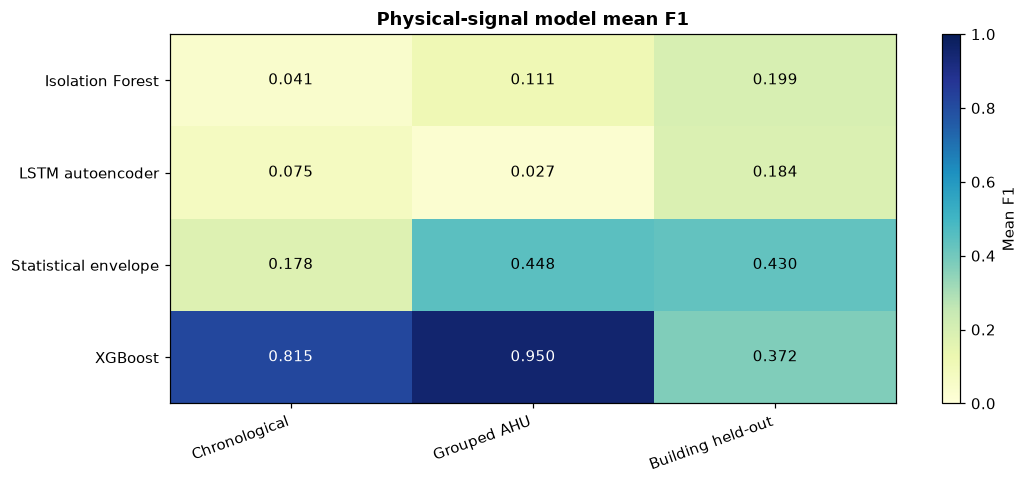

In [16]:
model_f1 = physical.pivot(index='model_label', columns='design', values='mean_f1').reindex(columns=DESIGN_ORDER)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(model_f1.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_title('Physical-signal model mean F1')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(model_f1.index)), model_f1.index)
for row in range(model_f1.shape[0]):
    for col in range(model_f1.shape[1]):
        value = model_f1.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > .55 else 'black')
fig.colorbar(im, ax=ax, label='Mean F1')
plt.tight_layout()
plt.show()

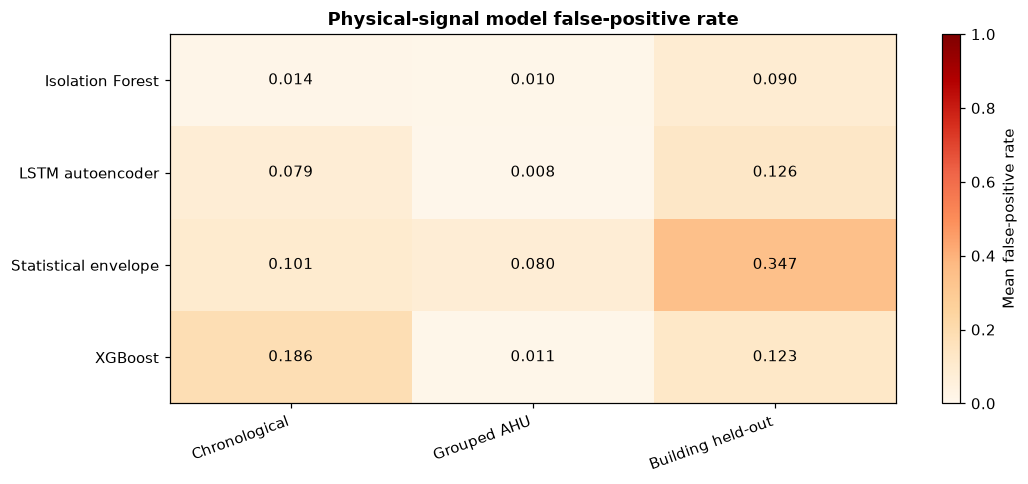

In [17]:
model_fpr = physical.pivot(index='model_label', columns='design', values='mean_false_positive_rate').reindex(columns=DESIGN_ORDER)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(model_fpr.to_numpy(), cmap='OrRd', vmin=0, vmax=1, aspect='auto')
ax.set_title('Physical-signal model false-positive rate')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(model_fpr.index)), model_fpr.index)
for row in range(model_fpr.shape[0]):
    for col in range(model_fpr.shape[1]):
        value = model_fpr.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > .55 else 'black')
fig.colorbar(im, ax=ax, label='Mean false-positive rate')
plt.tight_layout()
plt.show()

## Secondary comparison: XGBoost feature variants

Operational context adds missingness indicators, heating/cooling/idle mode flags and time-of-day features to the physical signals. It is retained as one focused sensitivity comparison rather than repeated for every model.

,design_label,variant,mean_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_false_positive_rate
7,Building held-out,operational_context,0.378,0.614,0.758,0.352,0.124
11,Building held-out,physical_signal,0.372,0.599,0.725,0.322,0.123
13,Chronological,operational_context,0.985,0.992,0.977,0.994,0.010
17,Chronological,physical_signal,0.815,0.903,0.690,0.993,0.186
19,Grouped AHU,operational_context,0.955,0.964,0.987,0.934,0.006
23,Grouped AHU,physical_signal,0.950,0.962,0.977,0.934,0.011


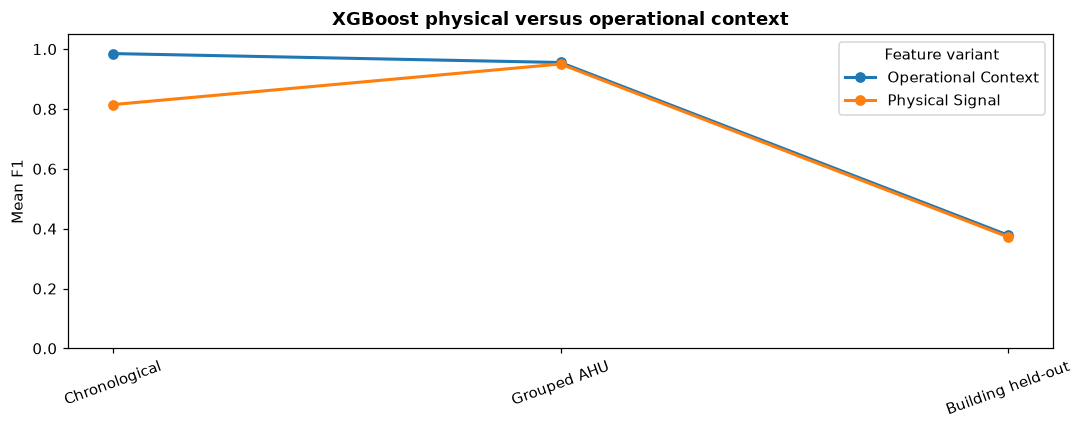

In [18]:
xgb_variants = detection_summary[
    (detection_summary['model'] == 'xgboost')
    & detection_summary['design'].isin(DESIGN_ORDER)
].copy()
xgb_variants['design_label'] = xgb_variants['design'].map(DESIGN_LABELS)
display(
    xgb_variants[['design_label', 'variant', 'mean_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']]
    .sort_values(['design_label', 'variant'])
    .style.format({column: '{:.3f}' for column in ['mean_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']})
)

fig, ax = plt.subplots(figsize=(10, 4))
for variant, group in xgb_variants.groupby('variant'):
    values = group.set_index('design').reindex(DESIGN_ORDER)['mean_f1']
    ax.plot([DESIGN_LABELS[d] for d in DESIGN_ORDER], values, marker='o', linewidth=2, label=variant.replace('_', ' ').title())
ax.set_title('XGBoost physical versus operational context')
ax.set_ylabel('Mean F1')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=20)
ax.legend(title='Feature variant')
plt.tight_layout()
plt.show()

## LSTM scoring coverage

The LSTM does not receive artificial predictions for the initial 11 rows of each test AHU. Those rows are reported as unscored because a complete 12-row history is not available.

,design_label,rows,scored_rows,unscored_rows,scored_rate
1,Building held-out,354504,354504,451,1.0
2,Chronological,70564,70564,451,1.0
3,Grouped AHU,354504,354504,451,1.0
0,ahu_held_out,77689,77689,99,1.0


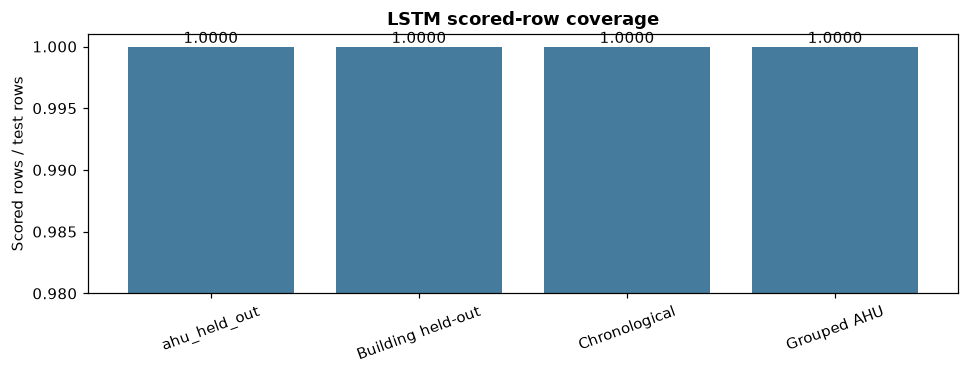

In [19]:
coverage = (
    detection_folds[detection_folds['model'] == 'lstm_autoencoder']
    .groupby(['design', 'model'], as_index=False)[['rows', 'scored_rows', 'unscored_rows']]
    .sum()
)
coverage['scored_rate'] = coverage['scored_rows'] / coverage['rows']
coverage['design_label'] = coverage['design'].map(DESIGN_LABELS).fillna(coverage['design'])
display(coverage[['design_label', 'rows', 'scored_rows', 'unscored_rows', 'scored_rate']].sort_values('design_label'))

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(coverage['design_label'], coverage['scored_rate'], color='#457b9d')
ax.set_title('LSTM scored-row coverage')
ax.set_ylabel('Scored rows / test rows')
ax.set_ylim(0.98, 1.001)
ax.tick_params(axis='x', rotation=20)
for bar, value in zip(bars, coverage['scored_rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.4f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Interpretation

* The normal operating-range rule is the strongest simple reference overall; the actuator/pump baseline is more conservative and provides a useful false-positive comparison.
* XGBoost is the strongest physical-signal model on chronological, grouped-AHU and within-dataset comparisons, but performance falls substantially on a completely unseen building.
* Isolation Forest and the LSTM autoencoder remain useful research comparisons, not assumed production winners.
* Operational context is treated as a sensitivity result. It is close to the physical XGBoost result for most split designs but changes chronological performance substantially, so it should not replace the physical-signal headline without a deployment decision.
* The building-held-out result is a transfer stress test on the canonical data. Office and hospital require their own cleaning policies before that result is presented as final production evidence.

## Reproducibility

The CSV results and manifests are generated artefacts and are ignored by Git. On a fresh checkout, run the audit, canonical-ingestion, split, three-baseline and four-model detection commands in `README.md`, then execute this notebook. The notebook is a presentation layer; the tested Python modules remain the source of truth.